# When does this house consume electricity?

**Three figures:** (1) daily, weekly, monthly and yearly changes; (2) typical hours, weekdays and months; (3) the largest hourly peak in context. Code and results are included. The original data and earlier notebooks remain unchanged.

**Source details matter:** `dataset_mansion.txt` specifies UTC timestamps. This notebook converts them to **Europe/Helsinki** for Finnish household clock-time patterns, including daylight saving. The local record covers **1 January 2016–31 May 2022**. The supplied notes describe electric heating, a heat pump installed during the study, after-work appliance use and a fireplace. These provide hypotheses, not confirmed explanations of consumption.

**Units:** the supplied documentation does not specify kWh or define whether each value is hourly energy. Charts therefore say **source units**. Period sums are sums of the reported hourly values; interpret them as energy totals only after confirming the measurement definition. Means compare consumption levels without giving longer months an automatic advantage.

In [1]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

DATA_PATH = Path('dataset_mansion.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('upload/dataset_mansion.csv')

raw = pd.read_csv(DATA_PATH, index_col=0)
timestamps = pd.to_datetime(raw['MTime'], utc=True, errors='raise')
assert timestamps.notna().all() and not timestamps.duplicated().any()
values = pd.to_numeric(raw['Consumption'].astype('string').str.replace(',', '.', regex=False), errors='raise')
consumption = pd.Series(values.to_numpy(dtype=float),
                        index=pd.DatetimeIndex(timestamps), name='Consumption').sort_index()
assert consumption.notna().all(), 'Investigate missing consumption before aggregation.'
assert consumption.index.equals(pd.date_range(consumption.index.min(), consumption.index.max(), freq='h'))

# A separate series: raw is not altered.
s = consumption.tz_convert('Europe/Helsinki')

def aggregate(series, frequency):
    table = series.resample(frequency, closed='left', label='left').agg(['mean', 'sum', 'count'])
    boundaries = pd.date_range(table.index[0], periods=len(table) + 1, freq=frequency)
    # Local days can contain 23 or 25 hours; count elapsed hours correctly.
    table['Expected hours'] = np.diff(boundaries.tz_convert('UTC').asi8) // (3600 * 10**9)
    table['Complete'] = table['count'].eq(table['Expected hours'])
    return table

daily = aggregate(s, 'D')
weekly = aggregate(s, 'W-MON')  # Monday through Sunday
monthly = aggregate(s, 'MS')
yearly = aggregate(s, 'YS')
full_years = yearly.index.year[yearly['Complete']]
typical = s[s.index.year.isin(full_years)]

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 125, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Local time range: {s.index.min()} to {s.index.max()}')
print('Complete years used for typical calendar patterns:', ', '.join(map(str, full_years)))
print('Local days with 23/24/25 hours:', daily['Expected hours'].value_counts().sort_index().to_dict())

Local time range: 2016-01-01 00:00:00+02:00 to 2022-05-31 23:00:00+03:00
Complete years used for typical calendar patterns: 2016, 2017, 2018, 2019, 2020, 2021
Local days with 23/24/25 hours: {23: 7, 24: 2330, 25: 6}


## 1. Changes over time

These charts use **mean hourly consumption within each period** so different period lengths are comparable. Incomplete weeks and years are excluded from their charts. All local days and months in this file are complete. The seven-day line smooths day-to-day variation; it does not remove seasonality.

Compare the repeating winter/summer cycle with the differences between years. The annual bars show observed differences, not weather-adjusted efficiency changes.

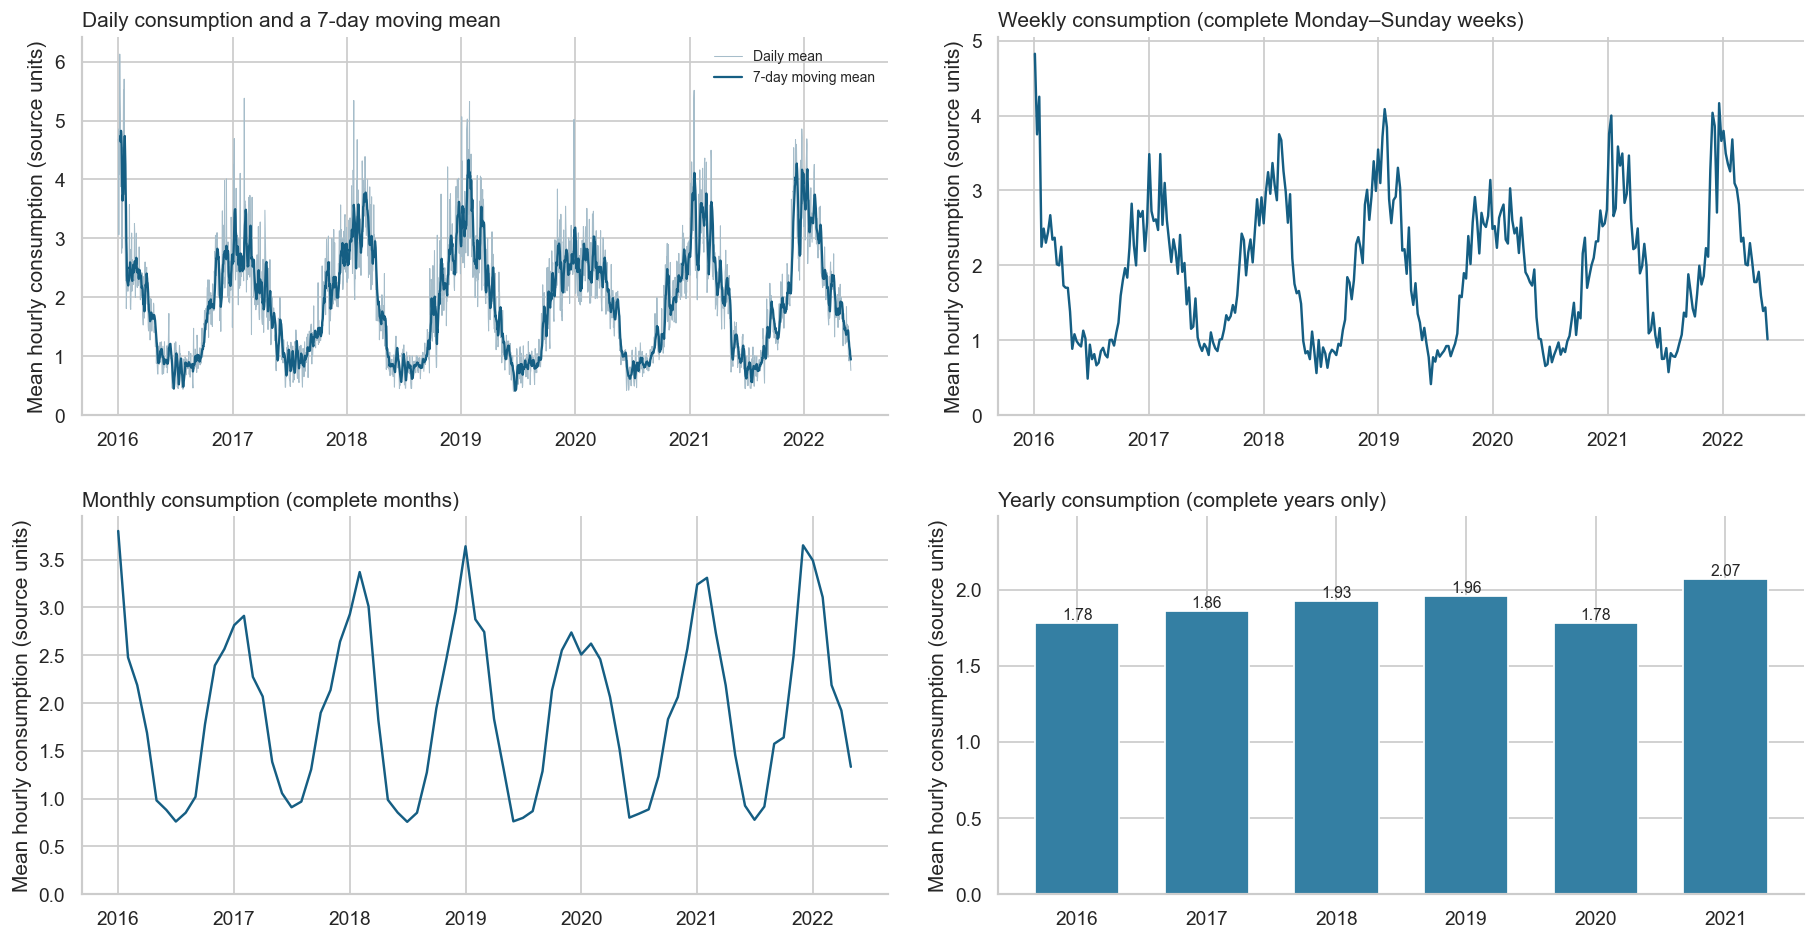

,Mean hourly value,Sum of hourly values,Observed hours,Coverage
Local year,,,,
2016,1.781,15642.64,8784,Full year
2017,1.857,16271.16,8760,Full year
2018,1.926,16873.09,8760,Full year
2019,1.958,17153.08,8760,Full year
2020,1.780,15638.66,8784,Full year
2021,2.067,18109.63,8760,Full year
2022,2.398,8686.92,3623,Partial: Jan–May


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
day = daily.loc[daily['Complete'], 'mean']
axes[0, 0].plot(day.index, day, color='#a6bdca', lw=.6, label='Daily mean')
axes[0, 0].plot(day.index, day.rolling(7, min_periods=7).mean(), color='#155e83', lw=1.3, label='7-day moving mean')
axes[0, 0].set_title('Daily consumption and a 7-day moving mean', loc='left')
axes[0, 0].legend(frameon=False, fontsize=8)
for ax, table, title in [
    (axes[0, 1], weekly, 'Weekly consumption (complete Monday–Sunday weeks)'),
    (axes[1, 0], monthly, 'Monthly consumption (complete months)')
]:
    valid = table.loc[table['Complete'], 'mean']
    ax.plot(valid.index, valid, color='#155e83', lw=1.4)
    ax.set_title(title, loc='left')
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.xaxis.set_major_locator(mdates.YearLocator(tz=s.index.tz))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y', tz=s.index.tz))
    ax.set_ylabel('Mean hourly consumption (source units)')
    ax.set_ylim(bottom=0)

annual = yearly.loc[yearly['Complete']]
axes[1, 1].bar(annual.index.year.astype(str), annual['mean'], color='#347fa3', width=.65)
for i, value in enumerate(annual['mean']):
    axes[1, 1].text(i, value + .025, f'{value:.2f}', ha='center', fontsize=9)
axes[1, 1].set_ylim(0, annual['mean'].max() * 1.2)
axes[1, 1].set_title('Yearly consumption (complete years only)', loc='left')
axes[1, 1].set_ylabel('Mean hourly consumption (source units)')
fig.tight_layout(pad=2)
plt.show()

# Totals are provided separately; 2022 is a partial year.
annual_summary = yearly.rename(columns={
    'mean': 'Mean hourly value', 'sum': 'Sum of hourly values', 'count': 'Observed hours'
}).copy()
annual_summary.index = annual_summary.index.year
annual_summary.index.name = 'Local year'
annual_summary['Coverage'] = np.where(annual_summary['Complete'], 'Full year', 'Partial: Jan–May')
display(annual_summary[['Mean hourly value', 'Sum of hourly values', 'Observed hours', 'Coverage']].round(3))

## 2. Typical hour, weekday and month

Use **complete years 2016–2021** for these comparisons so the extra winter/spring months in 2022 do not bias the averages. These are descriptive, pooled patterns; weather and changes in household routines are not controlled for.

- **Hourly lines:** compare weekday and weekend routines, in Finnish local time.
- **Weekday bars:** compare average hourly levels; this avoids giving a 25-hour daylight-saving day extra weight merely because it is longer.
- **Month curves:** thin lines are individual complete years; the bold line is the pooled seasonal profile. Repeated winter highs across years support seasonality.
- **Heatmap:** each cell is the mean for a particular weekday and clock hour. It is not a correlation chart. Repeated autumn clock hours both contribute to their clock-hour group.

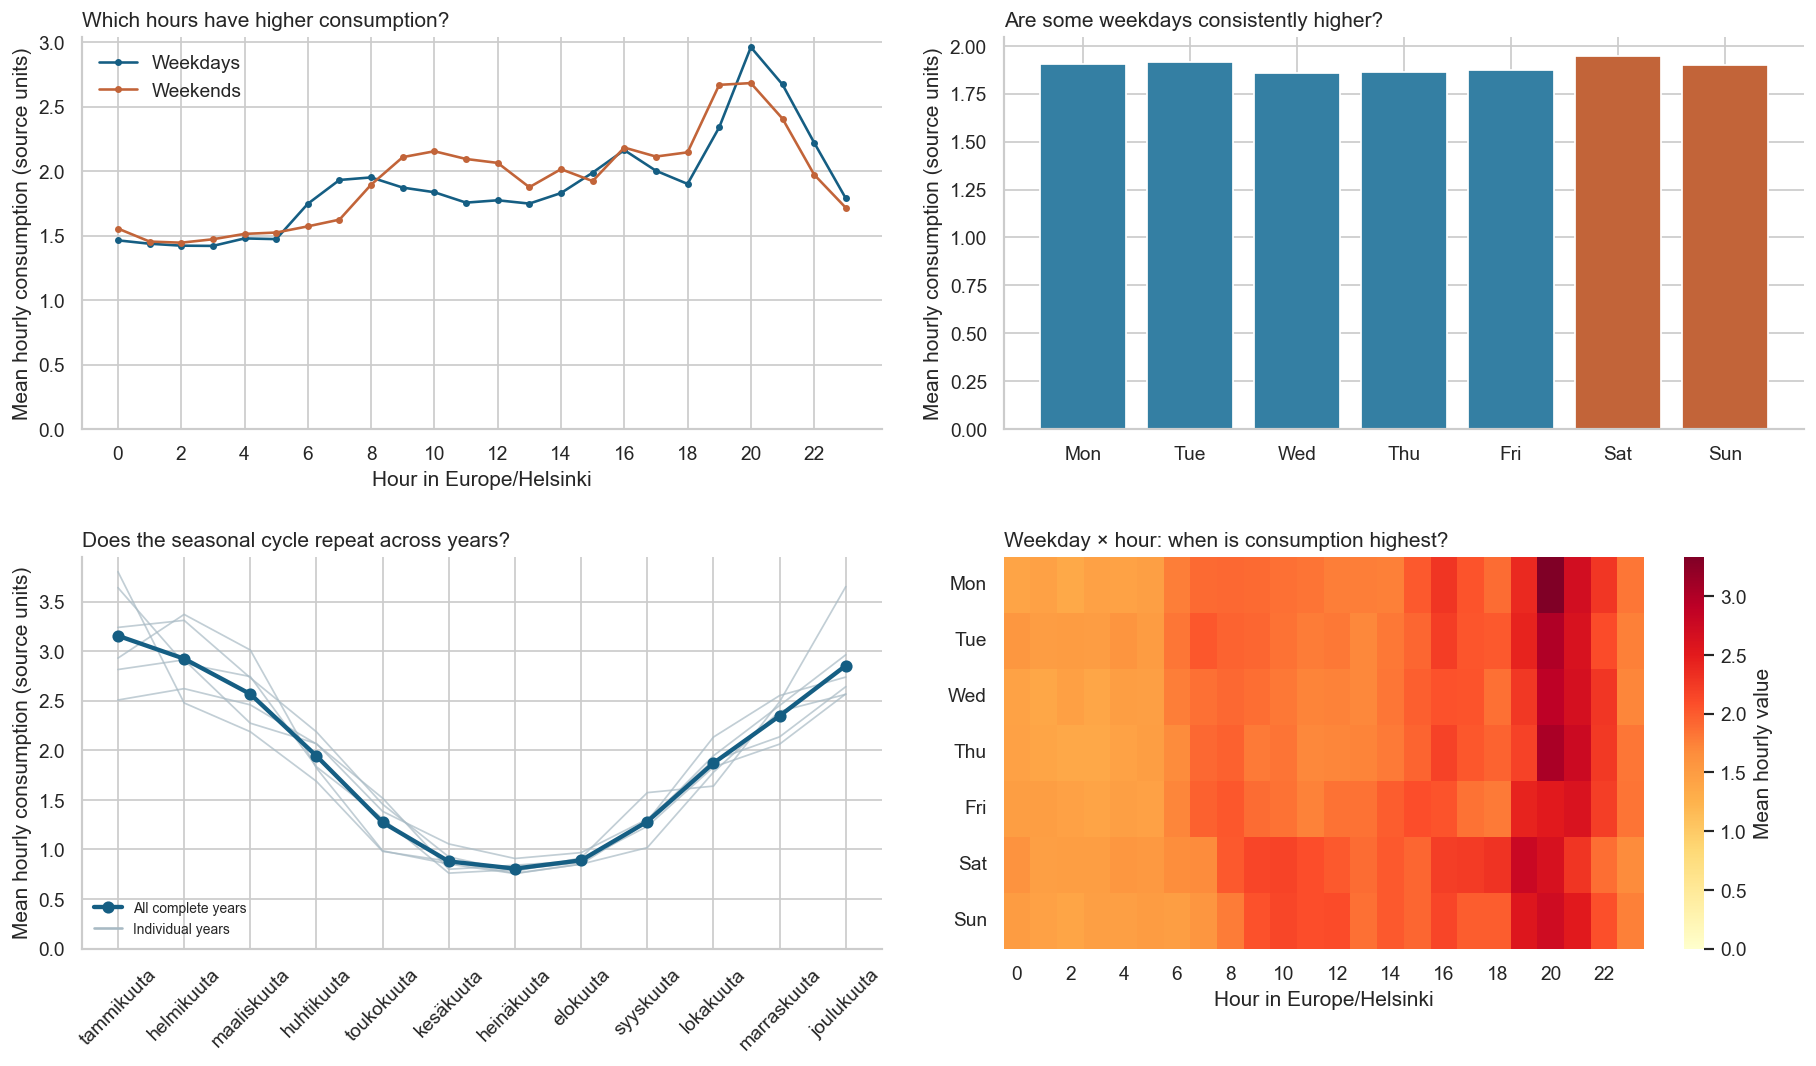

In [3]:
weekday_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
month_names = list(calendar.month_abbr)[1:]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for weekend, label, color in [(False, 'Weekdays', '#155e83'), (True, 'Weekends', '#c26439')]:
    part = typical[(typical.index.dayofweek >= 5) == weekend]
    profile = part.groupby(part.index.hour).mean().reindex(range(24))
    axes[0, 0].plot(profile.index, profile, label=label, color=color, marker='o', ms=3)
axes[0, 0].set_title('Which hours have higher consumption?', loc='left')
axes[0, 0].set_xlabel('Hour in Europe/Helsinki')
axes[0, 0].set_xticks(range(0, 24, 2))
axes[0, 0].legend(frameon=False)

weekday_mean = typical.groupby(typical.index.dayofweek).mean().reindex(range(7))
axes[0, 1].bar(weekday_names, weekday_mean, color=['#347fa3'] * 5 + ['#c26439'] * 2)
axes[0, 1].set_title('Are some weekdays consistently higher?', loc='left')

for year in full_years:
    part = typical[typical.index.year == year]
    profile = part.groupby(part.index.month).mean().reindex(range(1, 13))
    axes[1, 0].plot(range(1, 13), profile, color='#a8bac4', alpha=.7, lw=1)
month_profile = typical.groupby(typical.index.month).mean().reindex(range(1, 13))
axes[1, 0].plot(range(1, 13), month_profile, color='#155e83', lw=2.5, marker='o', label='All complete years')
axes[1, 0].plot([], [], color='#a8bac4', label='Individual years')
axes[1, 0].set_xticks(range(1, 13), month_names, rotation=45)
axes[1, 0].set_title('Does the seasonal cycle repeat across years?', loc='left')
axes[1, 0].legend(frameon=False, fontsize=8)

hour_day = pd.DataFrame({'Value': typical, 'Weekday': typical.index.dayofweek, 'Hour': typical.index.hour})
hour_day = hour_day.pivot_table(index='Weekday', columns='Hour', values='Value', aggfunc='mean').reindex(range(7))
hour_day.index = weekday_names
sns.heatmap(hour_day, ax=axes[1, 1], cmap='YlOrRd', vmin=0,
            xticklabels=2, yticklabels=True, cbar_kws={'label': 'Mean hourly value'})
axes[1, 1].set_title('Weekday × hour: when is consumption highest?', loc='left')
axes[1, 1].set_xlabel('Hour in Europe/Helsinki')
axes[1, 1].set_ylabel('')
axes[1, 1].tick_params(axis='y', rotation=0)
for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.set_ylim(bottom=0)
    ax.set_ylabel('Mean hourly consumption (source units)')
fig.tight_layout(pad=2)
plt.show()

## 3. High observations and spikes

The red points below are at or above the **global 99.5th percentile**: the highest roughly 0.5% of readings (ties can change the count). This is a descriptive screening rule, **not an anomaly test**. Winter heating can create high but normal values. The zoom shows whether the largest value is isolated or part of a sustained high-consumption period. No flagged values are removed.

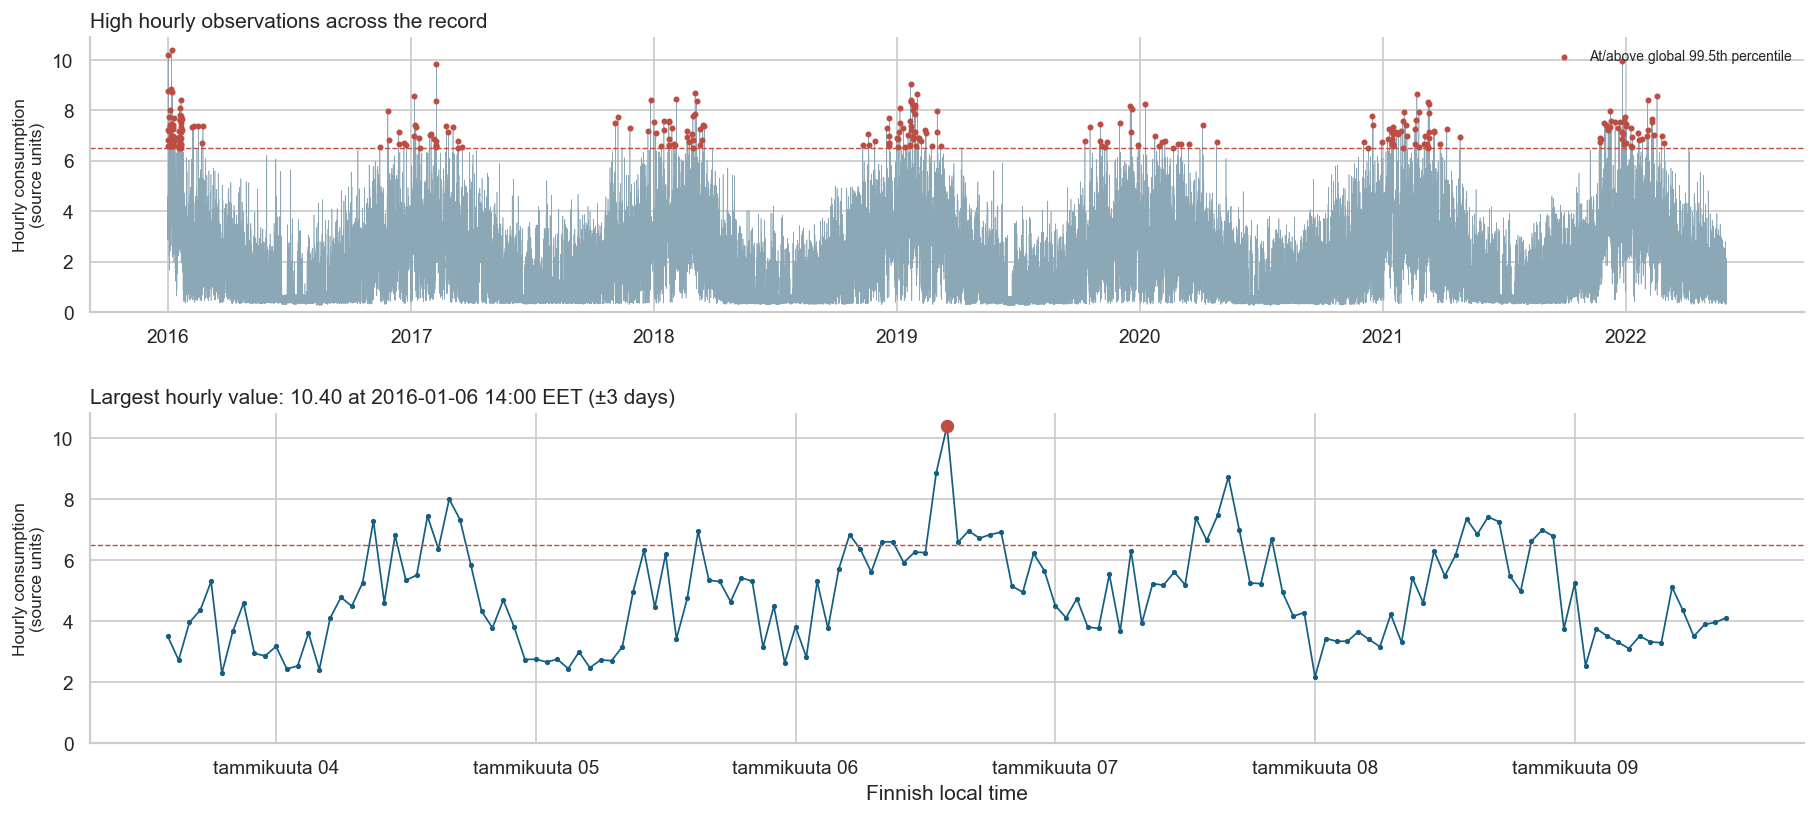

Global screening threshold: 6.51; flagged hours: 283


,Consumption
Finnish local timestamp,
2016-01-06 14:00 EET,10.40
2016-01-01 16:00 EET,10.20
2021-12-26 16:00 EET,9.96
2017-02-07 20:00 EET,9.83
2019-01-21 19:00 EET,9.06


In [4]:
threshold = s.quantile(.995)
flagged = s[s >= threshold]
peak_time = s.idxmax()
zoom = s.loc[peak_time - pd.Timedelta(days=3):peak_time + pd.Timedelta(days=3)]
fig, axes = plt.subplots(2, 1, figsize=(15, 7), gridspec_kw={'height_ratios': [1, 1.2]})
axes[0].plot(s.index, s, color='#8ca7b6', lw=.35)
axes[0].scatter(flagged.index, flagged, color='#bd4d42', s=6, label='At/above global 99.5th percentile', zorder=3)
axes[0].axhline(threshold, color='#bd4d42', lw=.8, ls='--')
axes[0].set_title('High hourly observations across the record', loc='left')
axes[0].legend(frameon=False, fontsize=8, loc='upper right')
axes[1].plot(zoom.index, zoom, color='#155e83', marker='o', ms=2, lw=1)
axes[1].scatter([peak_time], [s.max()], color='#bd4d42', s=45, zorder=4)
axes[1].axhline(threshold, color='#bd4d42', lw=.8, ls='--', label='Global 99.5th percentile')
axes[1].set_title(f'Largest hourly value: {s.max():.2f} at {peak_time:%Y-%m-%d %H:%M %Z} (±3 days)', loc='left')
axes[1].xaxis.set_major_locator(mdates.DayLocator(tz=s.index.tz))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d', tz=s.index.tz))
axes[1].set_xlabel('Finnish local time')
for ax in axes:
    ax.set_ylabel('Hourly consumption\n(source units)', fontsize=10)
    ax.set_ylim(bottom=0)
fig.tight_layout(pad=2)
plt.show()
print(f'Global screening threshold: {threshold:.2f}; flagged hours: {len(flagged):,}')
top_hours = s.nlargest(5).rename('Consumption').to_frame()
top_hours.index = top_hours.index.strftime('%Y-%m-%d %H:%M %Z')
top_hours.index.name = 'Finnish local timestamp'
display(top_hours)

## What the charts show

- **Daily routine:** the pooled hourly profile peaks around **20:00 Finnish local time**. This differs from the UTC peak because local clock time is 2–3 hours ahead. After-work appliance use is a plausible contributor, but is not separately measured.
- **Seasonality:** January has the highest mean hourly consumption and July the lowest in the complete years. Electric heating and the cold-season temperature relationship are consistent with this pattern; the charts do not establish a causal breakdown.
- **Weekly routine:** Saturday has the highest pooled weekday mean, but the weekday differences are much smaller than the winter/summer differences. This does not establish a statistically significant or universal Saturday effect.
- **Across years:** 2021 has the highest mean and summed consumption among complete years. Annual differences can reflect temperature, occupancy, equipment or habits. Do not compare the partial 2022 total with full years.
- **Spikes:** the largest hourly value is **10.40 at 14:00 EET on 6 January 2016**. Inspect its surrounding days before calling it an outlier or a recording error.

### Household context: useful hypotheses for later

The supplied house photograph mentions an electric boiler, a garage maintained around 10°C in winter, a heat pump installed during the evaluation period, a wood sauna, fireplace use after 20:00, work hours 08:00–16:00, and holidays. It also notes a change in everyday life from March 2020. These can motivate future comparisons, but appliance-level measurements, actual occupancy and the heat-pump installation date are not provided. Do not attribute a change to one of them from these charts alone.

**Next step:** describe these observed patterns in the EDA. No imputation, outlier removal, forecasting or feature changes are applied here.